# Introduction

This project is an **experimentation audit**, not a predictive model. The
goal isn't to build an uplift/CATE model that predicts which individual
customers are most likely to respond to an email — that's the usual
treatment of this dataset. Instead, this project asks a narrower,
business-first question: given a campaign that already ran, can we trust
the result enough to act on it, and is the result actually worth acting
on?

**The data:** Kevin Hillstrom's MineThatData email challenge — a real,
randomized marketing experiment where ~64,000 customers were split into
three groups (`Mens E-Mail`, `Womens E-Mail`, `No E-Mail`), with each
customer's pre-campaign purchase history and three tracked two-week
outcomes: did they visit, did they convert, and how much did they spend.

**The business question:** a growth team wants to win back dormant
customers with a targeted email. Before recommending this campaign be
scaled up, two things need to be true: the effect has to be real (not
noise, not an artifact of comparing unbalanced groups, not inflated by
running several tests at once), and the effect has to be a genuine
revenue win, not just an engagement bump that doesn't translate into
actual purchases — the "local maxima" trap, where a metric improves while
quietly failing to move the metric that actually matters.

**The decision this analysis supports:** should the company continue and
scale this win-back email program to its full dormant customer base, and
if so, which version — the Mens-styled or Womens-styled creative —
should be prioritized? Answering that well requires more than a single
significance test: it requires checking that the underlying experiment
was run correctly, that there's enough data to trust a null result if one
shows up, that testing multiple outcomes at once hasn't inflated the
chance of a false win, that the revenue estimate is as precise as
possible, and that competing explanations (like customers who would have
come back anyway) have been ruled out before crediting the campaign with
the full effect. That audit — not a prediction model — is what this
notebook walks through, end to end.

**Contents**
1. Pull & inspect the data
2. Define the dormant cohort
3. SRM check 
4. Power / MDE check 
5. Six-test Benjamini-Hochberg correction 
6. CUPED on spend 
7. Regression-to-the-mean check 
8. Guardrail synthesis — Verdict

## 1. Pull & inspect the data

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

In [2]:
from sklift.datasets import fetch_hillstrom

# target_col='all' returns visit, conversion, AND spend together --
# we need all three since step 5 tests all of them.
bunch = fetch_hillstrom(target_col='all')

X = bunch.data
y = bunch.target
treatment = bunch.treatment

df = pd.concat([X.reset_index(drop=True),
                treatment.reset_index(drop=True).rename('segment'),
                y.reset_index(drop=True)], axis=1)

print(bunch.DESCR)

Kevin Hillstrom Dataset: MineThatData

Data description
################

This is a copy of `MineThatData E-Mail Analytics And Data Mining Challenge dataset <https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html>`_.

This dataset contains 64,000 customers who last purchased within twelve months.
The customers were involved in an e-mail test.

* 1/3 were randomly chosen to receive an e-mail campaign featuring Mens merchandise.
* 1/3 were randomly chosen to receive an e-mail campaign featuring Womens merchandise.
* 1/3 were randomly chosen to not receive an e-mail campaign.

During a period of two weeks following the e-mail campaign, results were tracked.
Your job is to tell the world if the Mens or Womens e-mail campaign was successful.

Fields
################

Historical customer attributes at your disposal include:

* Recency: Months since last purchase.
* History_Segment: Categorization of dollars spent in the past year.
* History: Actual dollar value spe

In [3]:
print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()

Shape: (64000, 12)
Columns: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


**Sanity checks before trusting anything downstream** — confirm against
the documented dataset: total rows should be **64,000**, three segments
roughly equal thirds (checked formally in step 3, don't assume it here),
and `spend` should be heavily right-skewed (Day 1 habit — most customers
spend $0, so a plain mean/t-test on raw spend is already on shaky ground
before CUPED or anything else gets applied).

1. check the distribution of spend , conversion, recency of each of the different segments 
2. check if there are nulls, data types structural checks, duplicates 
3. 


In [ ]:
# Check for missing values
df.isna().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

In [26]:
df.describe(include='all')

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
count,64000.000000,64000,64000.000000,64000.000000,64000.000000,64000,64000.000000,64000,64000,64000.000000,64000.000000,64000.000000
unique,NaN,7,NaN,NaN,NaN,3,NaN,3,3,NaN,NaN,NaN
top,NaN,1) $0 - $100,NaN,NaN,NaN,Surburban,NaN,Web,Womens E-Mail,NaN,NaN,NaN
freq,NaN,22970,NaN,NaN,NaN,28776,NaN,28217,21387,NaN,NaN,NaN
mean,5.763734,NaN,242.085656,0.551031,0.549719,NaN,0.502250,NaN,NaN,0.146781,0.009031,1.050908
std,3.507592,NaN,256.158608,0.497393,0.497526,NaN,0.499999,NaN,NaN,0.353890,0.094604,15.036448
min,1.000000,NaN,29.990000,0.000000,0.000000,NaN,0.000000,NaN,NaN,0.000000,0.000000,0.000000
25%,2.000000,NaN,64.660000,0.000000,0.000000,NaN,0.000000,NaN,NaN,0.000000,0.000000,0.000000
50%,6.000000,NaN,158.110000,1.000000,1.000000,NaN,1.000000,NaN,NaN,0.000000,0.000000,0.000000
75%,9.000000,NaN,325.657500,1.000000,1.000000,NaN,1.000000,NaN,NaN,0.000000,0.000000,0.000000


In [43]:
conditions = [
    (df['mens'] == 1) & (df['womens'] == 1),
    (df['mens'] == 1) & (df['womens'] == 0),
    (df['mens'] == 0) & (df['womens'] == 1),
    (df['mens'] == 0) & (df['womens'] == 0),
]
choices = ['Both', 'Mens only', 'Womens only', 'Neither']
df['purchase_history_dept'] = np.select(conditions, choices, default='Unknown')

<h2> Historical spend distribution for all customers</h2>

<Axes: >

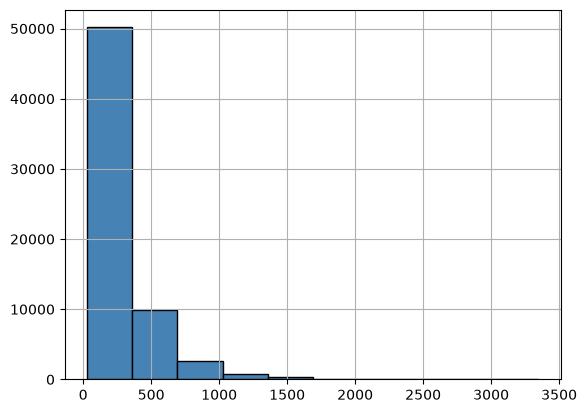

In [42]:
df['history'].hist(bins=10, color='steelblue', edgecolor='black')

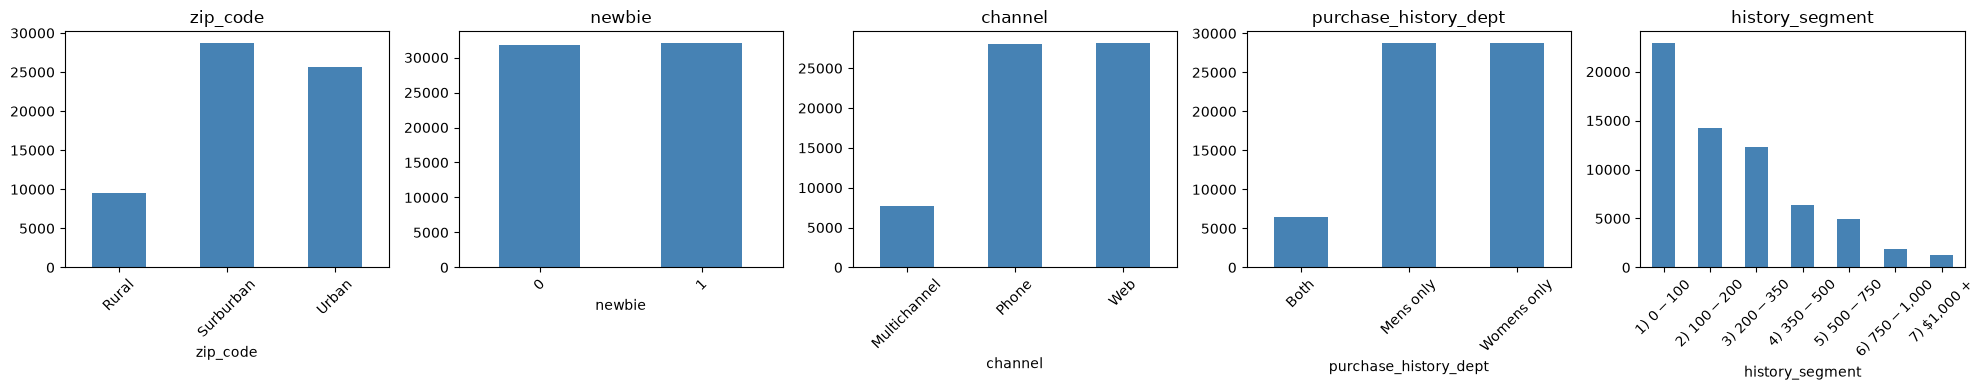

In [46]:
feature_cols = ['zip_code', 'newbie', 'channel', 'purchase_history_dept', 'history_segment']
fig, axes = plt.subplots(1, len(feature_cols), figsize=(4 * len(feature_cols), 4))

for ax, col in zip(axes, feature_cols):
    counts = df[col].value_counts().sort_index()
    #print(f"Distribution of {col}:")
    #print(counts)
    #print()
    counts.plot(kind='bar', ax=ax, title=col, color='steelblue')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

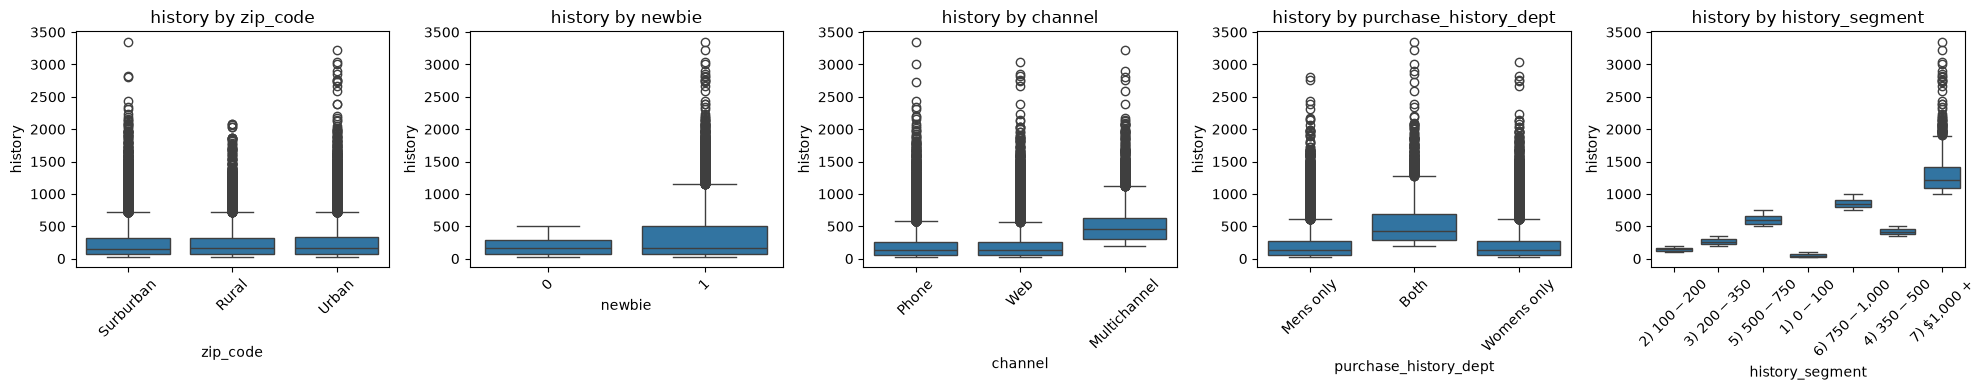

In [45]:
import seaborn as sns

fig, axes = plt.subplots(1, len(feature_cols), figsize=(4 * len(feature_cols), 4))

for ax, col in zip(axes, feature_cols):
    sns.boxplot(data=df, x=col, y='history', ax=ax)
    ax.set_title(f'history by {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

<h2> Analysis of distribution of <b>"historical spend"</b> compared with different categorical variables </h2>
1. Historical spend is right skewed<br>
2. Customers which buy for both genders tend to have higher median historical spend<br>
3. Customers which use both the channels tend to have higher median historical spend <br>
4. Strange thing about newbie - how come new customers have higher median historical spend need to confirm with the recency column to check whether this makes sense?
5. Customers have similar median historical spend regardless of their area of residence (suburban, rural, urban) <br>

<Axes: >

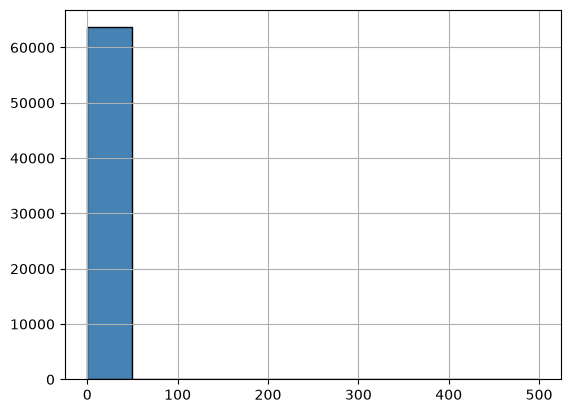

In [28]:
df['spend'].hist(bins=10, color='steelblue', edgecolor='black')

In [18]:
# baseline conversion rate
print(f"Baseline conversion rate (did not convert): {df['conversion'].value_counts()[0]/len(df)*100.00:.2f}%")
print(f"Baseline conversion rate (converted): {df['conversion'].value_counts()[1]/len(df)*100.00:.2f}%") 

Baseline conversion rate (did not convert): 99.10%
Baseline conversion rate (converted): 0.90%


<h2> Funnel of total customers vs customers which visited the site vs who finally made a purchase </h2>

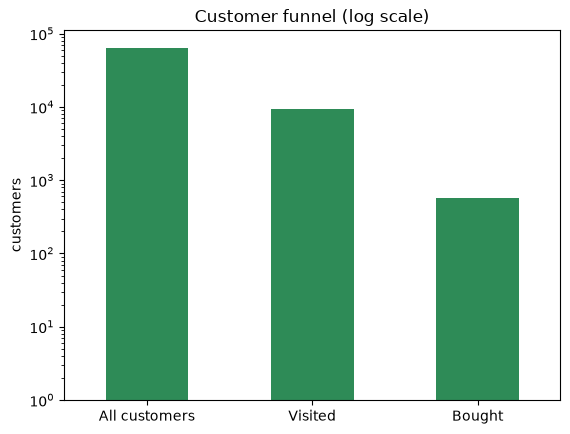

           stage  customers  pct_of_total
0  All customers      64000        100.00
1        Visited       9394         14.68
2         Bought        578          0.90


In [24]:
funnel = pd.Series({
    "All customers": len(df),
    "Visited": df["visit"].sum(),
    "Bought": df["conversion"].sum(),
})
funnel.plot(kind="bar", color="seagreen", log=True)
plt.title("Customer funnel (log scale)"); plt.ylabel("customers"); plt.xticks(rotation=0)
plt.show()

funnel_df = funnel.reset_index()
funnel_df.columns = ["stage", "customers"]
funnel_df["pct_of_total"] = (funnel_df["customers"] / funnel_df["customers"].iloc[0] * 100).round(2)
print(funnel_df)

- less than 1% customers made a purchase

In [47]:
assert df.shape[0] == 64000, f'expected 64,000 rows, got {df.shape[0]}'
print('Segment counts:')
print(df['segment'].value_counts())
print()
print('Spend distribution (expect heavy right-skew, most customers at 0):')
print(df['spend'].describe())
print('Share of customers with spend == 0:', (df['spend'] == 0).mean().round(4))

Segment counts:
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Spend distribution (expect heavy right-skew, most customers at 0):
count    64000.000000
mean         1.050908
std         15.036448
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        499.000000
Name: spend, dtype: float64
Share of customers with spend == 0: 0.991


<h2> Email segments and their vists vs conversion </h2>

- Visit: A customer which clicked on the email and came to the website <br>
- Conversion: A customer which came to the website and made a purchase <br>

In [49]:
df['segment'].value_counts()

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

In [56]:
print(df['visit'].value_counts())
print(f'Visit rate: {df["visit"].mean()*100:.2f}%')

visit
0    54606
1     9394
Name: count, dtype: int64
Visit rate: 14.68%


In [54]:
print(df['conversion'].value_counts())
print(f'Conversion rate: {df["conversion"].mean()*100:.2f}%')

conversion
0    63422
1      578
Name: count, dtype: int64
Conversion rate: 0.90%


<Axes: title={'center': 'Visit Rate by Segment'}, xlabel='segment'>

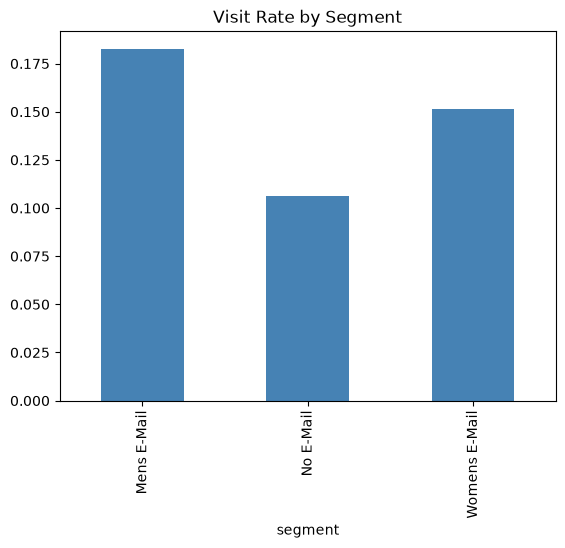

In [55]:
df.groupby('segment')['visit'].mean().plot(kind='bar', color='steelblue', title='Visit Rate by Segment')

<Axes: title={'center': 'Conversion Rate by Segment'}, xlabel='segment'>

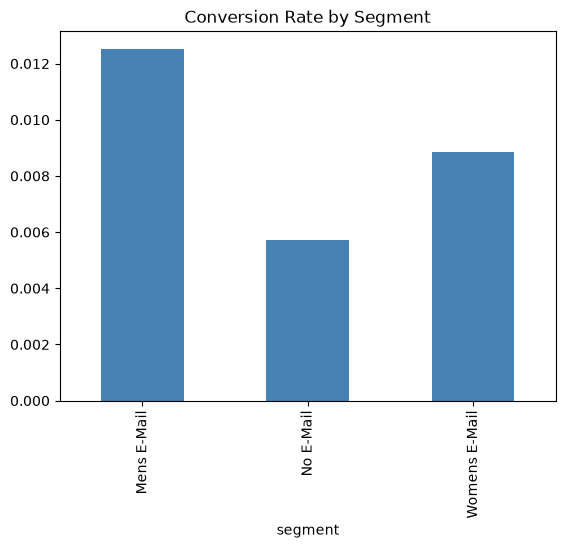

In [48]:
df.groupby('segment')['conversion'].mean().plot(kind='bar', color='steelblue', title='Conversion Rate by Segment')

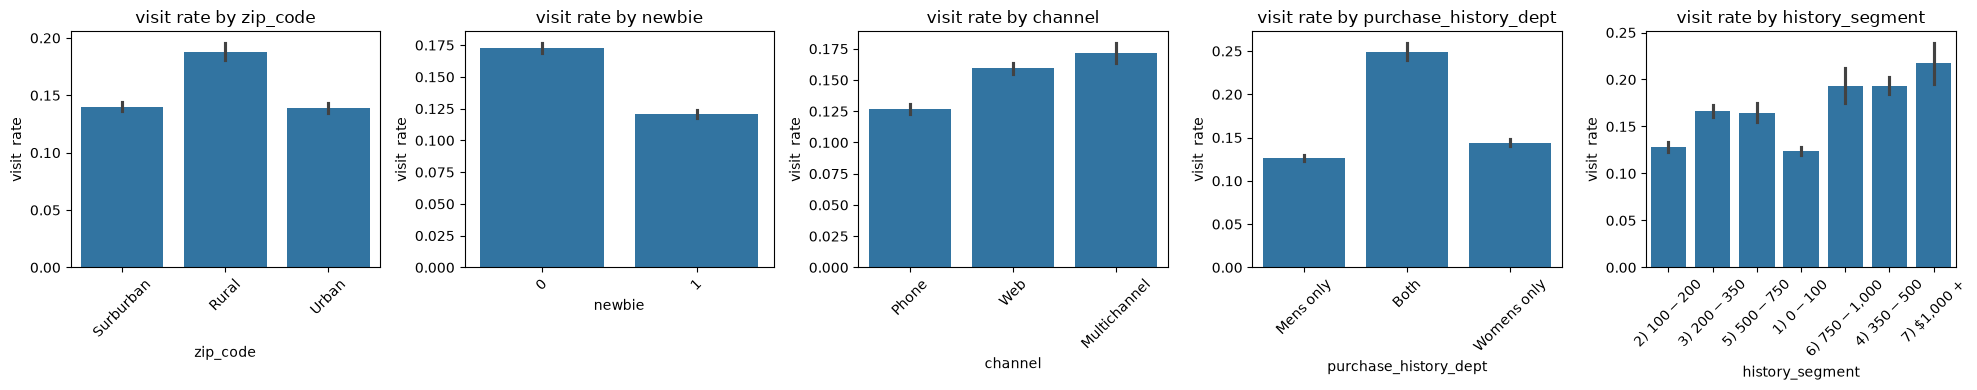

In [61]:
fig, axes = plt.subplots(1, len(feature_cols), figsize=(4 * len(feature_cols), 4))

for ax, col in zip(axes, feature_cols):
    sns.barplot(data=df, x=col, y='visit', ax=ax)
    ax.set_title(f'visit rate by {col}')
    ax.set_ylabel('visit  rate')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

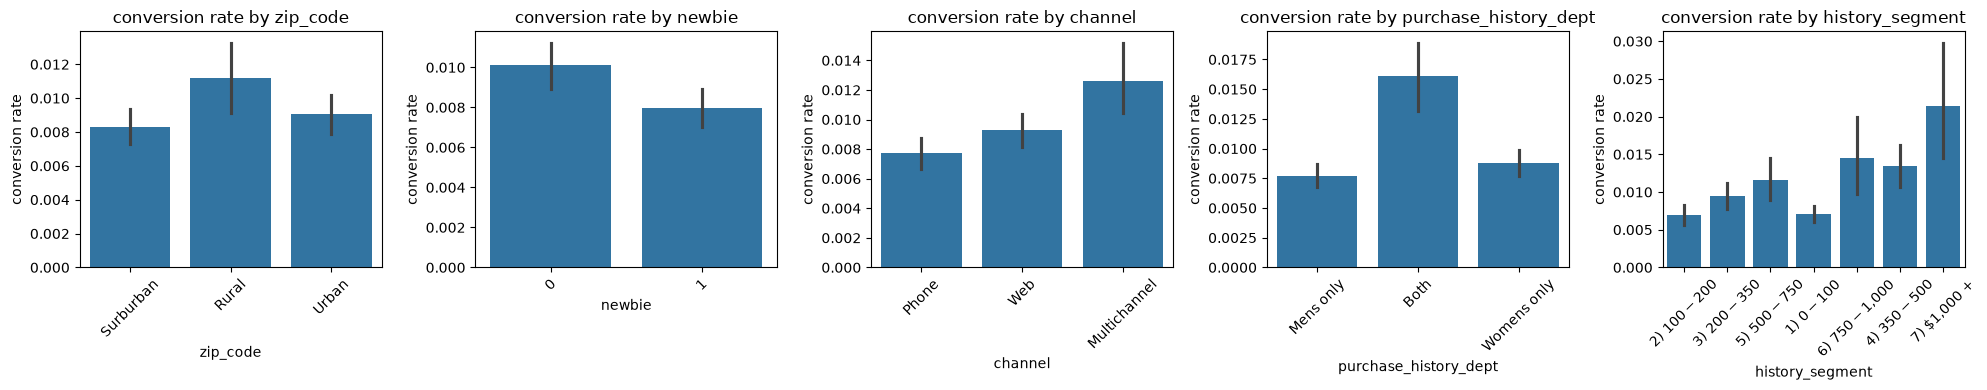

In [59]:
fig, axes = plt.subplots(1, len(feature_cols), figsize=(4 * len(feature_cols), 4))

for ax, col in zip(axes, feature_cols):
    sns.barplot(data=df, x=col, y='conversion', ax=ax)
    ax.set_title(f'conversion rate by {col}')
    ax.set_ylabel('conversion rate')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

channel    Multichannel     Phone       Web
zip_code                                   
Rural          0.014159  0.010012  0.011562
Surburban      0.011833  0.006948  0.008679
Urban          0.012946  0.007784  0.009205


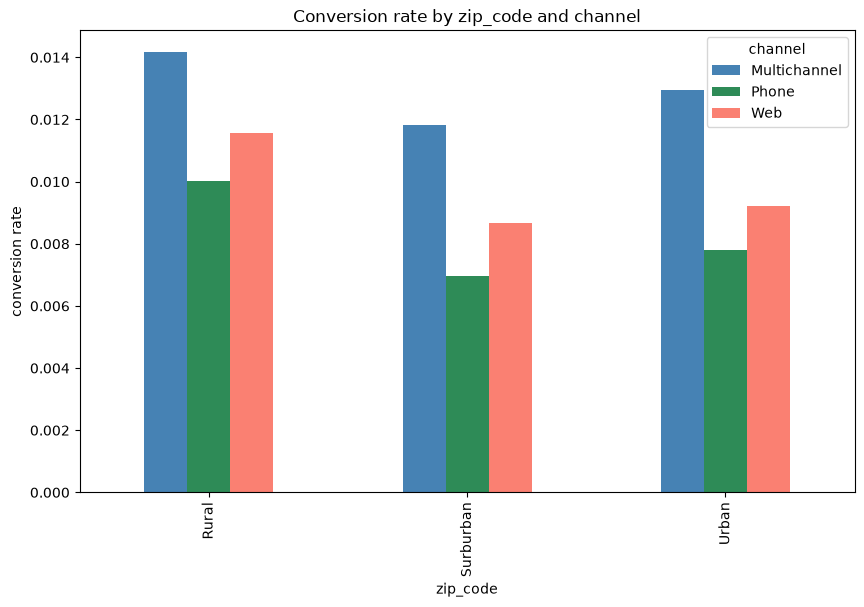

In [64]:
# full table: conversion rate for every zip_code x channel combination
conv_by_group = df.groupby(['zip_code', 'channel'])['conversion'].mean().unstack()
print(conv_by_group)

conv_by_group.plot(kind='bar', figsize=(10, 6), color=['steelblue', 'seagreen', 'salmon'])
plt.ylabel('conversion rate')
plt.title('Conversion rate by zip_code and channel')
plt.show()

purchase_history_dept      Both  Mens only  Womens only
zip_code                                               
Rural                  0.016807   0.010400     0.010738
Surburban              0.015422   0.006411     0.008631
Urban                  0.016648   0.008142     0.008193


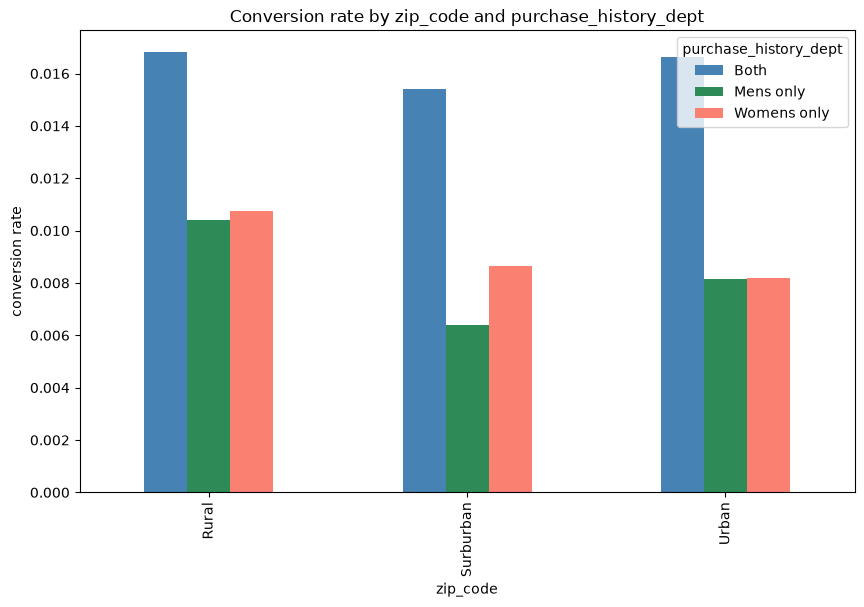

In [65]:
# full table: conversion rate for every zip_code x channel combination
conv_by_group = df.groupby(['zip_code', 'purchase_history_dept'])['conversion'].mean().unstack()
print(conv_by_group)

conv_by_group.plot(kind='bar', figsize=(10, 6), color=['steelblue', 'seagreen', 'salmon'])
plt.ylabel('conversion rate')
plt.title('Conversion rate by zip_code and purchase_history_dept')
plt.show()

- Customers residing in rural and who have bought in women dept historically converted better than historical male <br>
- Customers which use multichannel or who historically bought both dept convert better than single categories <br>
- Customers who got men's email converted better than women's email. <br>

<I>How are men's email converting better when historically women's dept brought more revenue? </I>


In [ ]:
df.groupby('segment')[['visit', 'conversion', 'spend']].mean()

,visit,conversion,spend
segment,,,
Mens E-Mail,0.182757,0.012531,1.422617
No E-Mail,0.106167,0.005726,0.652789
Womens E-Mail,0.151400,0.008837,1.077202


In [ ]:
# spend of customers who converted by segment 
df[df['conversion'] == 1].groupby('segment')['spend'].agg(['mean', 'median', 'count'])

,mean,median,count
segment,,,
Mens E-Mail,113.526929,66.980,267
No E-Mail,114.002705,88.365,122
Womens E-Mail,121.894762,94.710,189


In [79]:
seg_sum = df[df['conversion'] == 1].groupby('segment')['spend'].sum()
seg_sum / seg_sum.sum()

segment
Mens E-Mail      0.450677
No E-Mail        0.206790
Womens E-Mail    0.342533
Name: spend, dtype: float64

In [ ]:
summary = df.groupby('segment')[['visit', 'conversion', 'spend']].mean()
baseline = summary.loc['No E-Mail']

growth_pct = (summary - baseline) / baseline * 100
print(growth_pct.round(1))

baseline: visit         0.106167
conversion    0.005726
spend         0.652789
Name: No E-Mail, dtype: float64
               visit  conversion  spend
segment                                
Mens E-Mail     72.1       118.8  117.9
No E-Mail        0.0         0.0    0.0
Womens E-Mail   42.6        54.3   65.0


- Mens email brought more customers but the spend is close to what customers without no email spend
- Customers who converted from women email spend considerably more even though the volume is not as high

In [ ]:
# Local checkpoint so re-running later cells doesn't require re-downloading
import os
os.makedirs('data/raw', exist_ok=True)
df.to_csv('data/raw/hillstrom_combined.csv', index=False)
print('Saved checkpoint to data/raw/hillstrom_combined.csv')

## 2. Define the dormant cohort

`Recency` = months since last purchase. Look at its distribution first
(Day 1 habit) rather than picking a cutoff arbitrarily.

count    64000.000000
mean         5.763734
std          3.507592
min          1.000000
25%          2.000000
50%          6.000000
75%          9.000000
max         12.000000
Name: recency, dtype: float64


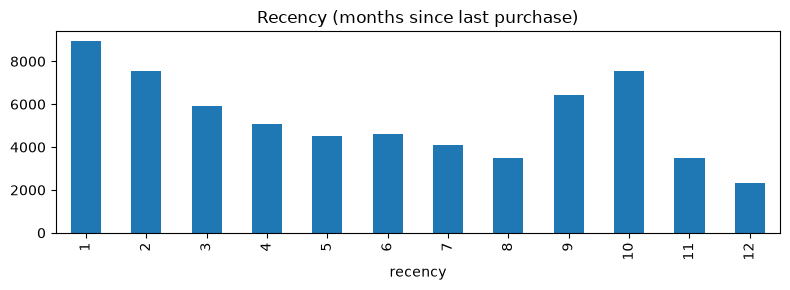

In [69]:
print(df['recency'].describe())
df['recency'].value_counts().sort_index().plot(kind='bar', figsize=(8,3), title='Recency (months since last purchase)')
plt.tight_layout()
#os.makedirs('figures', exist_ok=True)
#plt.savefig('figures/recency_distribution.png', dpi=120)
plt.show()

In [73]:
# "Dormant" = top quartile of recency (longest since last purchase).
# Document WHY this cutoff -- revisit once you've looked at the real
# distribution above; a business-meaningful cutoff (e.g. "9+ months")
# may read better in the writeup than a quantile.
RECENCY_DORMANT_THRESHOLD = df['recency'].quantile(0.75)
dormant = df[df['recency'] >= RECENCY_DORMANT_THRESHOLD].copy()

print(f'Dormant threshold (75th pct): Recency >= {RECENCY_DORMANT_THRESHOLD}')
print('Dormant cohort size:', len(dormant), f'({len(dormant)/len(df):.1%} of total)')
dormant['segment'].value_counts()

Dormant threshold (75th pct): Recency >= 9.0
Dormant cohort size: 19842 (31.0% of total)


segment
Mens E-Mail      6681
Womens E-Mail    6632
No E-Mail        6529
Name: count, dtype: int64

In [99]:
df.groupby('segment')[['visit','conversion']].mean()

,visit,conversion
segment,,
Mens E-Mail,0.182757,0.012531
No E-Mail,0.106167,0.005726
Womens E-Mail,0.151400,0.008837


In [101]:
print(growth_pct)

                   visit  conversion       spend
segment                                         
Mens E-Mail    72.140462  118.842188  117.928877
No E-Mail       0.000000    0.000000    0.000000
Womens E-Mail  42.605507   54.331304   65.015186


In [106]:
dormant.groupby('segment')[['visit','conversion', 'spend']].agg(['mean', 'count'])

visit       conversion           spend      
                   mean count       mean count      mean count
segment                                                       
Mens E-Mail    0.149079  6681   0.010477  6681  1.155373  6681
No E-Mail      0.074590  6529   0.002757  6529  0.362304  6529
Womens E-Mail  0.123945  6632   0.007388  6632  0.815124  6632

In [97]:
summary_dormant = dormant.groupby('segment')[['visit', 'conversion', 'spend']].mean()
baseline_dormant = summary_dormant.loc['No E-Mail']

growth_pct_dormant = (summary_dormant - baseline_dormant) / baseline_dormant * 100
print(growth_pct_dormant.round(1))

               visit  conversion  spend
segment                                
Mens E-Mail     99.9       280.0  218.9
No E-Mail        0.0         0.0    0.0
Womens E-Mail   66.2       168.0  125.0


In [ ]:
# Bootstrapping to estimate confidence intervals for the growth_pct_dormant values

In [102]:
rng = np.random.default_rng(42)
sub = dormant[dormant['segment'].isin(['Mens E-Mail', 'No E-Mail'])]
T = (sub['segment'] == 'Mens E-Mail').values.astype(int)
Y = sub['conversion'].values
n = len(sub)

boot_rel_lift = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    t, y = T[idx], Y[idx]
    treat_rate = y[t == 1].mean()
    control_rate = y[t == 0].mean()
    if control_rate > 0:
        boot_rel_lift.append((treat_rate - control_rate) / control_rate * 100)

boot_rel_lift = np.array(boot_rel_lift)
low, high = np.percentile(boot_rel_lift, [2.5, 97.5])
print(f"Dormant Mens E-Mail relative conversion lift: {boot_rel_lift.mean():.1f}%")
print(f"95% CI: {low:.1f}% to {high:.1f}%")

Dormant Mens E-Mail relative conversion lift: 304.0%
95% CI: 130.4% to 601.8%


In [105]:
# women's boostrap test for the dormant cohort
rng = np.random.default_rng(42)
sub = dormant[dormant['segment'].isin(['Womens E-Mail', 'No E-Mail'])]
T = (sub['segment'] == 'Womens E-Mail').values.astype(int)
Y = sub['conversion'].values
n = len(sub)

boot_rel_lift = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    t, y = T[idx], Y[idx]
    treat_rate = y[t == 1].mean()
    control_rate = y[t == 0].mean()
    if control_rate > 0:
        boot_rel_lift.append((treat_rate - control_rate) / control_rate * 100)

boot_rel_lift = np.array(boot_rel_lift)
low, high = np.percentile(boot_rel_lift, [2.5, 97.5])
print(f"Dormant Womens E-Mail relative conversion lift: {boot_rel_lift.mean():.1f}%")
print(f"95% CI: {low:.1f}% to {high:.1f}%")

Dormant Womens E-Mail relative conversion lift: 186.2%
95% CI: 61.3% to 390.1%


Within the dormant cohort, both emails lift visit, conversion, and spend well beyond what the whole population shows — Mens E-Mail’s conversion lift jumps to +280% (vs. +119% whole-population), Womens to +168% (vs. +54%). A bootstrap CI on the Mens dormant lift (130.4% to 601.8%) is wide, reflecting the control group’s small converter count (~18), but even its lower bound clears the whole-population estimate, and it never approaches zero — so dormant customers do appear genuinely more responsive to reactivation than average, not just an artifact of a noisy small sample. The magnitude is uncertain, not the direction. Even when comparing the dormant Womens E-Mail's conversion lift jumps 168% (vs +%54% for whole population). A bootstrap CI on the Womens dormant lift (61.3% to 390.1%) is wide, so dormant customers with womens e-mails do seem to have a genuine effect in conversion. <br>

Men's email may have converted more people(+118.8% vs +54.3%) but Women's email had a higher spend once converted (+$121 vs $113.5)<br>



## 3. SRM check (Day 9)

Chi-square goodness-of-fit against the expected split, run on the full
population first, then again within the dormant cohort — a dataset can
pass SRM overall and still fail it inside the one subgroup you actually
care about.

In [110]:
df['segment'].value_counts()

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

In [113]:
print(len(dormant))
dormant['segment'].value_counts()

19842


segment
Mens E-Mail      6681
Womens E-Mail    6632
No E-Mail        6529
Name: count, dtype: int64

In [109]:
def srm_check(segment_series, label):
    observed = segment_series.value_counts().sort_index()
    #print(observed)
    total = observed.sum()
    #print(len(observed))
    expected = pd.Series(total/len(observed), index=observed.index)
    chi2, p = stats.chisquare(f_obs=observed, f_exp=expected)
    verdict = 'PASS (no SRM detected)' if p > 0.01 else 'FAIL -- investigate randomization before trusting anything downstream'
    print(f'[{label}]')
    print('  observed:', dict(observed))
    print(f'  chi2={chi2:.4f}, p={p:.4f}  ->', verdict)
    print()
    return chi2, p

srm_check(df['segment'], 'Full population')
srm_check(dormant['segment'], 'Dormant cohort')

[Full population]
  observed: {'Mens E-Mail': np.int64(21307), 'No E-Mail': np.int64(21306), 'Womens E-Mail': np.int64(21387)}
  chi2=0.2025, p=0.9037  -> PASS (no SRM detected)

[Dormant cohort]
  observed: {'Mens E-Mail': np.int64(6681), 'No E-Mail': np.int64(6529), 'Womens E-Mail': np.int64(6632)}
  chi2=1.8201, p=0.4025  -> PASS (no SRM detected)



(np.float64(1.8200786211067432), np.float64(0.40250840089465395))

**SRM check result:** Both the full population (χ²=0.20, p=0.90) and the
dormant cohort specifically (χ²=1.82, p=0.40) pass — no sample ratio
mismatch detected in either case. Group sizes are close to the expected
even three-way split (21,307 / 21,306 / 21,387 overall; 6,681 / 6,529 /
6,632 within the dormant cohort), and neither p-value is anywhere near the
0.01 threshold that would flag a randomization problem. This clears the
first validity gate: the group comparisons in the steps that follow can be
trusted to be comparing like-for-like populations, not an artifact of a
broken or biased assignment process.

## 4. Power / MDE check (Day 8)

Given the dormant cohort's actual per-arm sample size, what's the
smallest lift in `visit` rate we could reliably detect at 80% power,
alpha=0.05? If the MDE turns out larger than any lift worth caring about,
say so explicitly rather than quietly reporting a non-significant result
as "no effect."

In [114]:
n_per_arm = dormant['segment'].value_counts().min()  # conservative: smallest arm
baseline_visit_rate = dormant.loc[dormant['segment'] == 'No E-Mail', 'visit'].mean()

analysis = NormalIndPower()

# Solve for MDE (the lift THIS sample size can detect), not just required n.
# solve_power solves for n given an effect size, not the reverse, so invert
# it with a small bisection search over candidate lift sizes.
def mde_for_n(n, baseline, alpha=0.05, power=0.8, lo=0.0001, hi=0.5, tol=1e-5):
    while hi - lo > tol:
        mid = (lo + hi) / 2
        es = proportion_effectsize(baseline, baseline + mid)
        achieved_power = analysis.power(effect_size=es, nobs1=n, alpha=alpha, ratio=1.0)
        if achieved_power < power:
            lo = mid
        else:
            hi = mid
    return hi

mde = mde_for_n(n_per_arm, baseline_visit_rate)
print(f'Smallest arm size in dormant cohort: {n_per_arm}')
print(f'Baseline (No E-Mail) visit rate in dormant cohort: {baseline_visit_rate:.4f}')
print(f'Minimum Detectable Effect (absolute, 80% power, alpha=0.05): {mde:.4f}')
print(f'  i.e. we can only reliably detect a visit-rate lift of {mde:.1%} or larger in this cohort size.')

Smallest arm size in dormant cohort: 6529
Baseline (No E-Mail) visit rate in dormant cohort: 0.0746
Minimum Detectable Effect (absolute, 80% power, alpha=0.05): 0.0134
  i.e. we can only reliably detect a visit-rate lift of 1.3% or larger in this cohort size.


In [116]:
n_per_arm = dormant['segment'].value_counts().min()  # conservative: smallest arm
baseline_conversion_rate = dormant.loc[dormant['segment'] == 'No E-Mail', 'conversion'].mean()

analysis = NormalIndPower()

# Solve for MDE (the lift THIS sample size can detect), not just required n.
# solve_power solves for n given an effect size, not the reverse, so invert
# it with a small bisection search over candidate lift sizes.
def mde_for_n(n, baseline, alpha=0.05, power=0.8, lo=0.0001, hi=0.5, tol=1e-5):
    while hi - lo > tol:
        mid = (lo + hi) / 2
        es = proportion_effectsize(baseline, baseline + mid)
        achieved_power = analysis.power(effect_size=es, nobs1=n, alpha=alpha, ratio=1.0)
        if achieved_power < power:
            lo = mid
        else:
            hi = mid
    return hi

mde = mde_for_n(n_per_arm, baseline_conversion_rate)
print(f'Smallest arm size in dormant cohort: {n_per_arm}')
print(f'Baseline (No E-Mail) conversion rate in dormant cohort: {baseline_conversion_rate:.4f}')
print(f'Minimum Detectable Effect (absolute, 80% power, alpha=0.05): {mde:.4f}')
print(f'  i.e. we can only reliably detect a conversion-rate lift of {mde:.1%} or larger in this cohort size.')

Smallest arm size in dormant cohort: 6529
Baseline (No E-Mail) conversion rate in dormant cohort: 0.0028
Minimum Detectable Effect (absolute, 80% power, alpha=0.05): 0.0032
  i.e. we can only reliably detect a conversion-rate lift of 0.3% or larger in this cohort size.


extra conversions at the MDE = 6,529 × 0.0032 ≈ 20.9 people<br>
No E-Mail avg order value:     $131.41  ->  20.9 × $131.41 ≈ $2,746 <br>
Mens E-Mail avg order value:   $110.28  ->  20.9 × $110.28 ≈ $2,304 <br>
Womens E-Mail avg order value: $110.33  ->  20.9 × $110.33 ≈ $2,305 <br>
2304/6681 => ~$0.345 per customer * (Number of dormant customers we will actually email during final rollout) => Final dollar value for mens email


## 5. Six-test Benjamini-Hochberg correction (Day 9)

Three outcomes (`visit`, `conversion`, `spend`) tested for each of the
two treatment arms against `No E-Mail` — six simultaneous tests. Running
six tests at alpha=0.05 each inflates the real false-positive rate well
above 5%, so none of them get trusted individually before BH correction.
`visit` and `conversion` are binary -> two-proportion z-test; `spend` is
continuous and heavily right-skewed with a point mass at zero -> Welch's
t-test (Day 4), the same judgment call flagged in the revision notes for
comparing group means under unequal variance without assuming normality
holds perfectly. All six tests are run on the **dormant cohort only** —
that's the population the business question is actually about.

In [133]:
results = []
for arm in ['Mens E-Mail', 'Womens E-Mail']:
    sub = dormant[dormant['segment'].isin([arm, 'No E-Mail'])]
    treat = sub[sub['segment'] == arm]
    control = sub[sub['segment'] == 'No E-Mail']
    nobs = np.array([len(treat), len(control)])

    for metric in ['visit', 'conversion']:
        count = np.array([treat[metric].sum(), control[metric].sum()])
        stat, p = proportions_ztest(count, nobs)
        results.append({'arm': arm, 'metric': metric, 'stat': stat, 'p_value': p})

    stat, p = stats.ttest_ind(treat['spend'], control['spend'], equal_var=False) #welch t-test
    results.append({'arm': arm, 'metric': 'spend', 'stat': stat, 'p_value': p})

results_df = pd.DataFrame(results)
reject, p_adj, _, _ = multipletests(results_df['p_value'], alpha=0.05, method='fdr_bh')
results_df['p_adj_bh'] = p_adj
results_df['significant_after_bh'] = reject
results_df

,arm,metric,stat,p_value,p_adj_bh,significant_after_bh
0,Mens E-Mail,visit,13.558907,7.017369e-42,4.210421e-41,True
1,Mens E-Mail,conversion,5.453835,4.929506e-08,9.859012e-08,True
2,Mens E-Mail,spend,3.548049,3.897938e-04,4.677526e-04,True
3,Womens E-Mail,visit,9.459076,3.106771e-21,9.320312e-21,True
4,Womens E-Mail,conversion,3.732821,1.893474e-04,2.840212e-04,True
5,Womens E-Mail,spend,2.440745,1.467126e-02,1.467126e-02,True


In [143]:
results = []
for arm in ['Mens E-Mail', 'Womens E-Mail']:
    sub = dormant[dormant['segment'].isin([arm, 'No E-Mail'])]
    treat = sub[sub['segment'] == arm]
    control = sub[sub['segment'] == 'No E-Mail']
    nobs = np.array([len(treat), len(control)])

    for metric in ['visit', 'conversion']:
        count = np.array([treat[metric].sum(), control[metric].sum()])
        stat, p = proportions_ztest(count, nobs)
        treat_rate, control_rate = treat[metric].mean(), control[metric].mean()
        abs_lift = treat_rate - control_rate
        rel_lift_pct = abs_lift / control_rate * 100
        results.append({'arm': arm, 'metric': metric, 'p_value': p,
                         'treat_rate': treat_rate, 'control_rate': control_rate,
                         'abs_lift': abs_lift, 'rel_lift_pct': rel_lift_pct})

    stat, p = stats.ttest_ind(treat['spend'], control['spend'], equal_var=False)
    treat_spend, control_spend = treat['spend'].mean(), control['spend'].mean()
    abs_lift = treat_spend - control_spend
    dollar_impact = abs_lift * len(treat)   # abs_lift is already $/customer, so x arm size = total extra $
    results.append({'arm': arm, 'metric': 'spend', 'p_value': p,
                     'treat_rate': treat_spend, 'control_rate': control_spend,
                     'abs_lift': abs_lift, 'rel_lift_pct': abs_lift/control_spend*100,
                     'dollar_impact': dollar_impact})

results_df = pd.DataFrame(results)
reject, p_adj, _, _ = multipletests(results_df['p_value'], alpha=0.05, method='fdr_bh')
results_df['p_adj_bh'] = p_adj
results_df['significant_after_bh'] = reject
results_df

,arm,metric,p_value,treat_rate,control_rate,abs_lift,rel_lift_pct,dollar_impact,p_adj_bh,significant_after_bh
0,Mens E-Mail,visit,7.017369e-42,0.149079,0.074590,0.074489,99.864460,NaN,4.210421e-41,True
1,Mens E-Mail,conversion,4.929506e-08,0.010477,0.002757,0.007721,280.041245,NaN,9.859012e-08,True
2,Mens E-Mail,spend,3.897938e-04,1.155373,0.362304,0.793070,218.896513,5298.499858,4.677526e-04,True
3,Womens E-Mail,visit,3.106771e-21,0.123945,0.074590,0.049354,66.167087,NaN,9.320312e-21,True
4,Womens E-Mail,conversion,1.893474e-04,0.007388,0.002757,0.004631,167.994404,NaN,2.840212e-04,True
5,Womens E-Mail,spend,1.467126e-02,0.815124,0.362304,0.452820,124.983609,3003.102732,1.467126e-02,True


**Read this table before moving on.** Anything that was significant raw
but drops out after the `p_adj_bh` correction was a false-discovery risk,
not a real effect — don't carry it into the write-up as a finding.

## 6. CUPED on spend (Day 10)

Each customer's pre-campaign spend (`History`) is a real, observed
covariate correlated with their post-campaign `spend` but untouched by the
campaign itself (it was recorded before the email went out) — exactly
what CUPED needs. `theta = Cov(History, spend) / Var(History)`; the
adjusted outcome is `spend - theta * (History - mean(History))`. This
should shrink the variance of the spend outcome, which tightens the CI on
the effect without needing more data.

In [125]:
dormant['history'].quantile([0,0.25,0.5,0.75,1])

0.00      29.9900
0.25      49.6600
0.50     118.5400
0.75     236.4175
1.00    1730.7300
Name: history, dtype: float64

In [ ]:
# Returns just the Spearman rho correlation coefficient
corr_s = dormant["spend"].corr(dormant["history"], method="spearman")
corr_p = dormant["spend"].corr(dormant["history"], method="pearson")
print(f"Spearman Correlation: {corr_s:.4f}")
print(f"Pearson Correlation: {corr_p:.4f}")


Spearman Correlation: 0.0052
Pearson Correlation: 0.0025


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

Correlation between the 2 variable is really low, CUPED might not reduce much for the variance here and expectation is that pre reduction and post reduction variance will more or less be same

In [118]:
Xc = dormant['history']
Yc = dormant['spend']
theta = np.cov(Xc, Yc)[0, 1] / np.var(Xc)
dormant['spend_cuped'] = Yc - theta * (Xc - Xc.mean())

print(f'theta = {theta:.4f}')
print('Variance before CUPED:', round(Yc.var(), 4))
print('Variance after CUPED :', round(dormant["spend_cuped"].var(), 4))
print(f'Variance reduction: {(1 - dormant["spend_cuped"].var() / Yc.var()):.2%}')

theta = 0.0002
Variance before CUPED: 161.1183
Variance after CUPED : 161.1172
Variance reduction: 0.00%


In [132]:
print('Spend effect, raw vs. CUPED-adjusted:')
for arm in ['Mens E-Mail', 'Womens E-Mail']:
    sub = dormant[dormant['segment'].isin([arm, 'No E-Mail'])]
    treat = sub[sub['segment'] == arm]
    control = sub[sub['segment'] == 'No E-Mail']

    stat_raw, p_raw = stats.ttest_ind(treat['spend'], control['spend'], equal_var=False) #welch t-test
    stat_cuped, p_cuped = stats.ttest_ind(treat['spend_cuped'], control['spend_cuped'], equal_var=False) #welch t-test
    print(f'  {arm}: raw p={p_raw:.4f}  ->  CUPED p={p_cuped:.4f}')

Spend effect, raw vs. CUPED-adjusted:
  Mens E-Mail: raw p=0.0004  ->  CUPED p=0.0004
  Womens E-Mail: raw p=0.0147  ->  CUPED p=0.0146


**CUPED result:** theta came out to ≈0.0002, with essentially 0% variance
reduction (161.12 before vs. 161.12 after) — CUPED did not help here.
This is because `History` and `spend` were only weakly correlated within
the dormant cohort specifically: selecting customers purely on `Recency`
pulls together both former big spenders and former small spenders who
have all since gone quiet, which erases most of History's usual ability
to predict future spend. 

## 7. Regression-to-the-mean check (Day 11)

The dormant cohort was selected *because* it sits in the extreme tail
of `Recency`. Whenever you select a group on an extreme value of one
variable and then remeasure a related outcome, some reversion toward the
population average is expected on statistical grounds alone — with zero
campaign effect. The honest check: does the `No E-Mail` **control** arm
inside the dormant cohort already look meaningfully less "dead" than a
naive "most dormant customers never come back" view would predict,
compared to the control arm in the general population? If so, some of
whatever "recovery" shows up in the treatment arms needs to be weighed
against this before crediting the campaign for all of it.

In [141]:
overall_control_visit = df.loc[df['segment'] == 'No E-Mail', 'visit'].mean()
dormant_control_visit = dormant.loc[dormant['segment'] == 'No E-Mail', 'visit'].mean()
non_dormant_control_visit = df.loc[(df['segment'] == 'No E-Mail') &
                                    (df['recency'] < RECENCY_DORMANT_THRESHOLD), 'visit'].mean()

print(f'Control-arm visit rate, whole population:        {overall_control_visit:.4f}')
print(f'Control-arm visit rate, non-dormant customers:    {non_dormant_control_visit:.4f}')
print(f'Control-arm visit rate, dormant cohort:            {dormant_control_visit:.4f}')
print()
print(f'dormant control visit rate as a pct of non-dormant control visit rate: {dormant_control_visit / non_dormant_control_visit:.2%}')
print()
print('If the dormant-control rate sits much closer to the non-dormant-control')
print('rate than a "dormant = gone" story predicts, flag that explicitly in the')
print('writeup as a competing explanation alongside the campaign effect.')

Control-arm visit rate, whole population:        0.1062
Control-arm visit rate, non-dormant customers:    0.1201
Control-arm visit rate, dormant cohort:            0.0746

dormant control visit rate as a pct of non-dormant control visit rate: 62.10%

If the dormant-control rate sits much closer to the non-dormant-control
rate than a "dormant = gone" story predicts, flag that explicitly in the
writeup as a competing explanation alongside the campaign effect.


In [ ]:
overall_control_conversion = df.loc[df['segment'] == 'No E-Mail', 'conversion'].mean()
dormant_control_conversion = dormant.loc[dormant['segment'] == 'No E-Mail', 'conversion'].mean()
non_dormant_control_conversion = df.loc[(df['segment'] == 'No E-Mail') &
                                        (df['recency'] < RECENCY_DORMANT_THRESHOLD), 'conversion'].mean()

print(f'Control-arm conversion rate, whole population:        {overall_control_conversion:.4f}')
print(f'Control-arm conversion rate, non-dormant customers:    {non_dormant_control_conversion:.4f}')
print(f'Control-arm conversion rate, dormant cohort:            {dormant_control_conversion:.4f}')
print()
print(f'dormant control conversion rate as a pct of non-dormant control conversion rate: {dormant_control_conversion / non_dormant_control_conversion:.2%}')
print()

Control-arm conversion rate, whole population:        0.0057
Control-arm conversion rate, non-dormant customers:    0.0070
Control-arm conversion rate, dormant cohort:            0.0028

dormant control conversion rate as a pct of non-dormant control conversion rate: 39.17%

If the dormant-control rate sits much closer to the non-dormant-control
rate than a "dormant = gone" story predicts, flag that explicitly in the
writeup as a competing explanation alongside the campaign effect.


**What we found:** Dormant customers who got no email still visited the
site occasionally, but almost never completed a purchase — their
conversion rate was only 40% of what a typical active customer shows,
compared to 62% for visits. In other words, dormancy mostly affects
whether someone buys, not whether they browse.

**Why it matters:** Because dormant customers rarely purchase on their
own, we can trust that a jump in purchases from this email is largely a
real result of the campaign, not customers who were going to buy anyway.
The visit numbers deserve a bit more caution, since a fair number of
dormant customers were still showing up occasionally even without any
email — so some of that visit increase likely would have happened
regardless.

,mean,median,count
segment,,,
Mens E-Mail,110.272143,61.870,70
No E-Mail,131.415556,113.185,18
Womens E-Mail,110.324490,82.510,49


## 8. Guardrail synthesis — the actual verdict

Pull it together. Fill this in once the real numbers are in front of
you — the structure of the argument is what matters:

- **Visit** — did any arm clear BH correction in step 5? If yes, the
  engagement lift is real, not a multiple-testing artifact.
- **Conversion** — did it move in the same direction as visit? If visit
  moved but conversion didn't, that's an early local-maxima warning sign.
- **Spend (CUPED-adjusted)** — did the tightened estimate clear BH
  correction? This is the guardrail: an email that drives visits without
  moving spend is a hollow win, exactly the Topic 2 trap.
- **Regression to the mean** — does step 7's control-arm comparison explain
  away part of the effect? If the dormant-control group already looks
  less dead than expected, discount the treatment-effect claim
  accordingly before writing the conclusion.

**Verdict:** _(write 2-3 sentences here once the real results are in,
answering both halves of the business question from the top of this
notebook.)_

## Verdict
- Visit: The engagement lift is real since there is almost a 100% lift for mens email and around 66% lift for womens email in visits and p value for both of them are less than 0.05 proving the statistical significance<br>
- Conversion: conversion and visit moved in the same direction, and there is a greater relative lift in conversion compared to visit, which means that people who did visit after seeing the email converted at a greater rate than ones who converted without seeing the email <br>
- Spend (CUPED): As we see in section 6, history and spend are not really correlated strongly with less than 5% of variability being explained so we dont get any change in the variance reduction before and after. No change to BH correction. <br>
- Regression to mean: Dormant customers usually had as much as 62% visit as the non-dormant ones without any emails so dormant customers were visiting the website but were not converting, around 40% of conversion for dormant customers compared to non-dormant cusotmers which is why the email campaign did help in increasing the conversion. <br>

During the experiment we saw that the sales increased ~8k in 2 weeks in treatement group<br>
Men's email brought us volume with higher number of conversions while women's email had a higher mean spend $121.894762 compared to mens email spend $113.526 vs No email group who converted had a mean spend of $114. so if we want volume we can send mens email but if we want higher spend dormant customers 


## What extra data would strengthen this analysis

**Timestamps / calendar dates.** The dataset has no actual send date or
purchase dates, only `Recency` (months since last purchase). Without real
dates, seasonality can't be tested at all — we can't tell whether this
result would hold if the campaign ran during a holiday period vs. a quiet
month, or whether the lift is specific to whenever this particular send
happened to occur.

**A customer ID and repeat observations.** This is a single snapshot —
one campaign, one two-week outcome window, no way to follow the same
customer over time. With repeat-campaign data we could check whether the
win-back effect persists beyond two weeks, whether reactivated customers
stay active or churn again quickly, and whether sending this email
repeatedly to the same dormant customers causes fatigue/diminishing
returns over time (directly relevant given the counterintuitive `newbie`
finding from earlier).

**Campaign cost data.** We only have revenue impact, not cost — no cost
per email sent, no discount costs if any were offered. Without this, the
dollar figures in this project are gross revenue lift, not true profit or
ROI; a real business decision needs the net number.

**A long-run outcome window.** All outcomes here are measured over just
two weeks. A longer follow-up window would let us estimate actual
incremental customer lifetime value from this campaign, rather than a
one-time revenue bump.

**Creative/content-level metadata.** We can see which arm a customer got,
but not what was actually in the email (subject line, products featured,
send time, discount size). Without this, any theory for *why* Mens
E-Mail outperforms Womens E-Mail is speculation, not something testable.

**A larger sample in key subgroups.** Some of the sharpest findings in
this project — the dormant control's ~18 converters, the median spend
comparison on 70 vs. 49 converters — rest on quite small subgroups. More
data would tighten the bootstrap intervals and make the median-vs-mean
finding more robust.

**Channel-level visibility beyond this one experiment.** We can't tell
whether this email is creating genuinely incremental revenue or simply
pulling forward purchases customers would have made anyway through
another channel (e.g., a paid ad they'd have clicked regardless). A
broader incrementality view across channels would address this.

**Richer customer-level covariates.** Beyond zip category, demographic or
behavioral data would let us build real heterogeneous treatment effect
analysis — i.e., which specific types of dormant customers respond best
— rather than only comparing broad segments like `channel` or
`purchase_history_dept`.